# CED6150 — Module 7 Applied Case Study
## Predicting next-day market volatility with liquidity indicators

**Research question:** Do liquidity proxies and market risk indicators help identify high-volatility days in U.S. equity ETFs?

- **Data stream A:** SPY / QQQ daily OHLCV (market liquidity)
- **Data stream B:** VIX index (market risk)
- **Time:** 2018–2025; final untouched out-of-time test = 2025
- **Models:** Regularized logistic regression vs random forest; K-means regimes
- **Decision:** flag high-risk days using a cost-aware classification threshold

**Data access:** Yahoo Finance via `yfinance`. VIX measures implied volatility rather than liquidity. The *Corwin–Schultz spread* is a proxy based on daily highs/lows, **not an observed quoted/effective bid–ask spread**. Results here will be computed live; the notebook contains no predetermined findings.

**References:** Corwin & Schultz (2012), *Journal of Finance*, https://doi.org/10.1111/j.1540-6261.2012.01729.x; Amihud (2002), *Journal of Financial Markets*; yfinance documentation https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html

**Workflow note:** Run all cells top to bottom in Google Colab. Exports are written to `/content/module7_outputs` (or `module7_outputs` outside Colab). Check printed diagnostics and figure contents before submission.

In [1]:
!pip -q install yfinance scikit-learn
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.cluster import KMeans
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings('ignore', category=FutureWarning)
OUT = Path('module7_outputs'); OUT.mkdir(exist_ok=True)
SEED = 42
START, END = '2018-01-01', '2026-01-01'  # end exclusive
print('Output folder:', OUT.resolve())

Output folder: /content/module7_outputs


## 1. Download and validate the two data streams

In [2]:
def fetch_one(ticker):
    df = yf.download(ticker, start=START, end=END, auto_adjust=False,
                     group_by='column', progress=False, threads=False)
    if df is None or df.empty:
        raise RuntimeError(f'No data downloaded for {ticker}. Retry Colab / check network access.')
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df = df.reset_index()
    df.columns = [str(x).strip().lower().replace(' ', '_') for x in df.columns]
    df['date'] = pd.to_datetime(df['date']).dt.tz_localize(None).dt.normalize()
    required = ['date','open','high','low','close','volume'] if ticker != '^VIX' else ['date','close']
    missing = [x for x in required if x not in df.columns]
    if missing: raise ValueError(f'{ticker} missing columns {missing}: {df.columns.tolist()}')
    return df.sort_values('date').drop_duplicates('date')

spy, qqq, vix = fetch_one('SPY'), fetch_one('QQQ'), fetch_one('^VIX')
print('Rows downloaded:', {'SPY':len(spy), 'QQQ':len(qqq), 'VIX':len(vix)})
for label, table in [('SPY',spy), ('QQQ',qqq), ('VIX',vix)]:
    print(label, table['date'].min().date(), table['date'].max().date(),
          'missing close', table['close'].isna().sum())
assert len(spy)>1200 and len(qqq)>1200 and len(vix)>1200, 'Data coverage is insufficient.'


Rows downloaded: {'SPY': 2011, 'QQQ': 2011, 'VIX': 2011}
SPY 2018-01-02 2025-12-31 missing close 0
QQQ 2018-01-02 2025-12-31 missing close 0
VIX 2018-01-02 2025-12-31 missing close 0


## 2. Two liquidity measures and tidy ETF-date panel

Amihud (daily proxy) = |daily return| / dollar volume (USD). We scale by $10^9$ for readability. Corwin–Schultz spread is estimated from adjacent daily high/low ratios. Negative raw spread estimates are clipped at zero, as a practical approximation; clearly disclose this treatment.

In [3]:
def add_liquidity(frame, ticker):
    x = frame[['date','open','high','low','close','volume']].copy().sort_values('date')
    x['ticker'] = ticker
    x['ret'] = x['close'].pct_change()
    x['dollar_volume'] = x['close'] * x['volume']
    x['amihud_1e9'] = (x['ret'].abs() / x['dollar_volume'].replace(0,np.nan))*1e9
    # Two-day Corwin-Schultz high-low spread estimate
    hl2 = np.log(x['high']/x['low']).pow(2)
    beta = hl2 + hl2.shift(1)
    high2 = pd.concat([x['high'],x['high'].shift(1)],axis=1).max(axis=1)
    low2 = pd.concat([x['low'],x['low'].shift(1)],axis=1).min(axis=1)
    gamma = np.log(high2/low2).pow(2)
    denom = 3 - 2*np.sqrt(2)
    alpha = (np.sqrt(2*beta)-np.sqrt(beta))/denom - np.sqrt(gamma/denom)
    alpha = alpha.clip(lower=0, upper=20)  # avoid negative/noisy estimates
    x['cs_spread'] = 2*np.expm1(alpha)/(1+np.exp(alpha))
    x['vol_10d'] = x['ret'].rolling(10).std()
    x['amihud_5d'] = x['amihud_1e9'].rolling(5).mean()
    x['spread_5d'] = x['cs_spread'].rolling(5).mean()
    return x

panel = pd.concat([add_liquidity(spy,'SPY'), add_liquidity(qqq,'QQQ')], ignore_index=True)
panel = panel.merge(vix[['date','close']].rename(columns={'close':'vix_close'}), on='date',how='left')
panel = panel.sort_values(['ticker','date']).reset_index(drop=True)
assert not panel.duplicated(['ticker','date']).any()
panel.to_csv(OUT/'tidy_market_panel.csv', index=False)
print('Panel shape:', panel.shape)
print(panel[['ticker','date','amihud_1e9','cs_spread','vix_close']].tail())
print('\nMissing values by column:\n',panel.isna().sum())

Panel shape: (4022, 15)
     ticker       date  amihud_1e9  cs_spread  vix_close
4017    SPY 2025-12-24    0.000129   0.000000      13.47
4018    SPY 2025-12-26    0.000004   0.000000      13.60
4019    SPY 2025-12-29    0.000083   0.000000      14.20
4020    SPY 2025-12-30    0.000038   0.002014      14.33
4021    SPY 2025-12-31    0.000147   0.000000      14.95

Missing values by column:
 date              0
open              0
high              0
low               0
close             0
volume            0
ticker            0
ret               2
dollar_volume     0
amihud_1e9        2
cs_spread         2
vol_10d          20
amihud_5d        10
spread_5d        10
vix_close         0
dtype: int64


## 3. Next-day label and features

Forecast is made **after the close of date t**, using information available by then, to predict the magnitude of the SPY return on the **next trading day**. The high-risk cutoff is defined in advance as a fixed 1.5% absolute daily move, so no future target values are needed to define labels.

In [4]:
s = panel[panel.ticker=='SPY'].set_index('date').sort_index()
q = panel[panel.ticker=='QQQ'].set_index('date').sort_index()
d = pd.DataFrame(index=s.index)
for col in ['amihud_5d','spread_5d','vol_10d','ret']:
    d['spy_'+col] = s[col]
    d['qqq_'+col] = q[col].reindex(d.index)
d['vix_close'] = s['vix_close']
d['vix_change_1d'] = d['vix_close'].pct_change(fill_method=None)
d['vix_lag1'] = d['vix_close'].shift(1)
# Feature at t, label relates to return at t+1
d['next_abs_spy_ret'] = s['ret'].shift(-1).abs()
features = ['spy_amihud_5d','spy_spread_5d','spy_vol_10d','spy_ret',
            'qqq_amihud_5d','qqq_spread_5d','qqq_vol_10d','qqq_ret',
            'vix_close','vix_change_1d','vix_lag1']
d = d.dropna(subset=features+['next_abs_spy_ret']).sort_index()
train_mask = d.index < '2025-01-01'
cutoff = 0.015  # fixed ex-ante 1.5% absolute next-day return threshold
d['high_risk_next_day'] = (d['next_abs_spy_ret'] > cutoff).astype(int)
train = d.loc[train_mask].copy(); test = d.loc[~train_mask].copy()
# Purge last training timestamp so its t+1 label cannot be a test-period observation
train = train.iloc[:-1].copy()
assert train.index.max() < test.index.min()
assert len(test)>150
print('Fixed ex-ante high-risk cutoff:',round(float(cutoff)*100,3),'% absolute daily return')
print('Train dates:',train.index.min().date(),train.index.max().date(), 'N=',len(train))
print('Test dates:',test.index.min().date(),test.index.max().date(), 'N=',len(test))
print('Class balance: train',train.high_risk_next_day.mean().round(3),
      ', test',test.high_risk_next_day.mean().round(3))
d.to_csv(OUT/'model_dataset.csv',index_label='date')

Fixed ex-ante high-risk cutoff: 1.5 % absolute daily return
Train dates: 2018-01-17 2024-12-30 N= 1750
Test dates: 2025-01-02 2025-12-30 N= 249
Class balance: train 0.142 , test 0.133


## 4. Unsupervised regimes (train-only fit)

        spy_amihud_5d  spy_spread_5d  spy_vol_10d  vix_close  \
regime                                                         
0              0.0004         0.0037       0.0149    25.6662   
1              0.0007         0.0159       0.0529    58.3596   
2              0.0002         0.0017       0.0069    16.3696   

        high_risk_next_day interpreted_label  
regime                                        
0                   0.2729   Moderate stress  
1                   0.7200     Higher stress  
2                   0.0676      Lower stress  


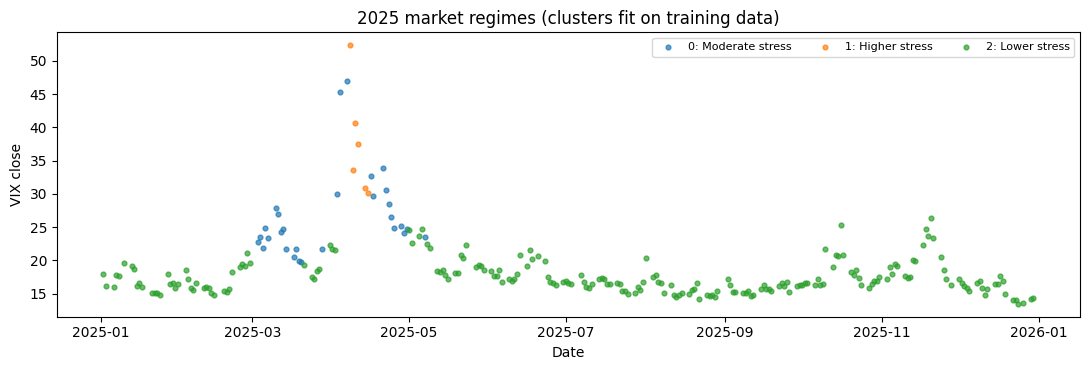

In [5]:
cluster_features = ['spy_amihud_5d','spy_spread_5d','spy_vol_10d','vix_close']
cluster_pipe = Pipeline([('imputer',SimpleImputer(strategy='median')),
                         ('scaler',StandardScaler())])
ztrain = cluster_pipe.fit_transform(train[cluster_features])
ztest = cluster_pipe.transform(test[cluster_features])
km = KMeans(n_clusters=3,n_init=15,random_state=SEED)
train['regime'] = km.fit_predict(ztrain)
test['regime'] = km.predict(ztest)
summary = train.groupby('regime')[cluster_features+['high_risk_next_day']].mean()
# Descriptive risk labels sorted by cluster's mean VIX; assess economically before reporting
ordered = summary['vix_close'].sort_values().index.tolist()
labels = {ordered[0]:'Lower stress',ordered[1]:'Moderate stress',ordered[2]:'Higher stress'}
summary['interpreted_label'] = [labels[i] for i in summary.index]
summary.to_csv(OUT/'cluster_summary.csv')
print(summary.round(4))
fig,ax=plt.subplots(figsize=(11,3.8))
for k in sorted(test['regime'].unique()):
    p=test[test.regime==k]
    ax.scatter(p.index,p.vix_close,s=12,label=f'{k}: {labels[k]}',alpha=.7)
ax.set(title='2025 market regimes (clusters fit on training data)',ylabel='VIX close',xlabel='Date')
ax.legend(fontsize=8,ncol=3);fig.tight_layout();fig.savefig(OUT/'cluster_regimes.png',dpi=180);plt.show()

## 5. Liquidity measures through time

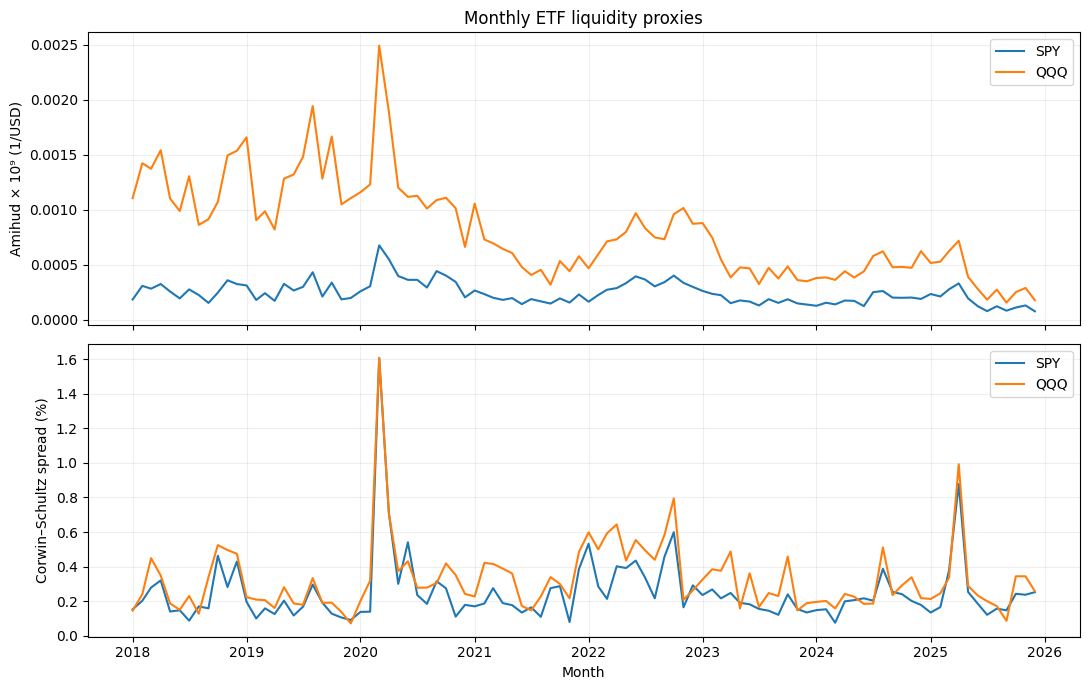

In [6]:
monthly = panel.set_index('date').groupby('ticker')[['amihud_1e9','cs_spread']].resample('MS').mean().reset_index()
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
for t in ['SPY','QQQ']:
    p=monthly[monthly.ticker==t]
    axes[0].plot(p.date,p.amihud_1e9,label=t)
    axes[1].plot(p.date,p.cs_spread*100,label=t)
axes[0].set(ylabel='Amihud × 10⁹ (1/USD)',title='Monthly ETF liquidity proxies')
axes[1].set(ylabel='Corwin–Schultz spread (%)',xlabel='Month')
for a in axes:a.legend();a.grid(alpha=.2)
fig.tight_layout();fig.savefig(OUT/'liquidity_over_time.png',dpi=180);plt.show()

## 6. Regularized GLM vs random forest: expanding time-series validation

Five sequential validation windows, with a one-row purge gap. Preprocessing (imputation/scaling) is fit **inside each training fold only**.

                            auc          pr_auc        
                           mean     std    mean     std
model                                                  
Random forest             0.758  0.0697  0.3687  0.1467
Regularized logistic GLM  0.772  0.0711  0.3845  0.2029

Validation windows:
                    model  fold  train_end validation_start validation_end      auc   pr_auc
Regularized logistic GLM     1 2019-03-19       2019-03-21     2020-05-14 0.891616 0.696143
           Random forest     1 2019-03-19       2019-03-21     2020-05-14 0.880793 0.573520
Regularized logistic GLM     2 2020-05-13       2020-05-15     2021-07-12 0.700109 0.229549
           Random forest     2 2020-05-13       2020-05-15     2021-07-12 0.732571 0.225645
Regularized logistic GLM     3 2021-07-09       2021-07-13     2022-09-06 0.753923 0.393352
           Random forest     3 2021-07-09       2021-07-13     2022-09-06 0.731622 0.380780
Regularized logistic GLM     4 2022-09-02       2022-0

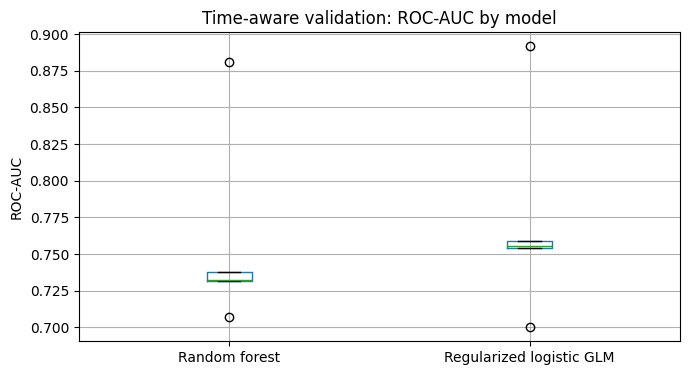

In [7]:
X=train[features]; y=train['high_risk_next_day']
models = {
 'Regularized logistic GLM': Pipeline([('imputer',SimpleImputer(strategy='median')),
        ('scale',StandardScaler()),('model',LogisticRegression(C=.3,penalty='l2',max_iter=2000,random_state=SEED))]),
 'Random forest': Pipeline([('imputer',SimpleImputer(strategy='median')),
        ('model',RandomForestClassifier(n_estimators=200,max_depth=6,min_samples_leaf=12,
                  random_state=SEED,n_jobs=-1))])
}
cv=TimeSeriesSplit(n_splits=5,gap=1)
cv_rows=[]; oof={name:pd.Series(np.nan,index=train.index,dtype=float) for name in models}
for fold,(tr,va) in enumerate(cv.split(X),1):
    assert tr.max()+1 < va.min(), 'Insufficient chronological gap'
    for name,est in models.items():
        est.fit(X.iloc[tr],y.iloc[tr])
        p=est.predict_proba(X.iloc[va])[:,1]
        oof[name].iloc[va] = p
        cv_rows.append({'model':name,'fold':fold,'train_end':str(X.index[tr[-1]].date()),
                        'validation_start':str(X.index[va[0]].date()),
                        'validation_end':str(X.index[va[-1]].date()),
                        'auc':roc_auc_score(y.iloc[va],p) if y.iloc[va].nunique()>1 else np.nan,
                        'pr_auc':average_precision_score(y.iloc[va],p)})
cv_results=pd.DataFrame(cv_rows)
cv_results.to_csv(OUT/'validation_windows.csv',index=False)
comparison=cv_results.groupby('model')[['auc','pr_auc']].agg(['mean','std']).round(4)
comparison.to_csv(OUT/'model_comparison.csv')
print(comparison)
print('\nValidation windows:\n',cv_results.to_string(index=False))
fig,ax=plt.subplots(figsize=(7,4))
cv_results.boxplot(column='auc',by='model',ax=ax)
plt.suptitle('');ax.set(title='Time-aware validation: ROC-AUC by model',ylabel='ROC-AUC',xlabel='')
fig.tight_layout();fig.savefig(OUT/'model_comparison.png',dpi=180);plt.show()

## 7. Cost matrix, threshold and untouched 2025 test

**Illustrative costs only:** false negative = 5 units (missed risky day); false positive = 1 unit (unnecessary alarm). These are not observed investment losses. Choose threshold on out-of-fold training predictions, never on 2025 test outcomes.

Selected model (highest mean validation ROC-AUC): Regularized logistic GLM
Threshold selected using OOF predictions: 0.26
2025 ROC-AUC: 0.8037
2025 PR-AUC: 0.4319
Confusion matrix [[TN,FP],[FN,TP]]:
 [[207   9]
 [ 24   9]]
              precision    recall  f1-score   support

           0       0.90      0.96      0.93       216
           1       0.50      0.27      0.35        33

    accuracy                           0.87       249
   macro avg       0.70      0.62      0.64       249
weighted avg       0.84      0.87      0.85       249

Test illustrative total loss units: 129


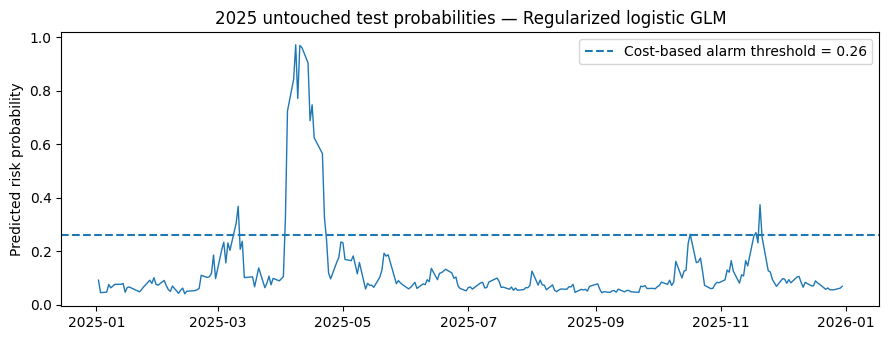

In [8]:
winner = cv_results.groupby('model')['auc'].mean().idxmax()
valid=oof[winner].notna(); yp=y.loc[valid].to_numpy(); pp=oof[winner].loc[valid].to_numpy()
thresholds=np.arange(.10,.91,.01)
fn_cost,fp_cost=5,1
costs=[]
for th in thresholds:
    predicted=(pp>=th).astype(int)
    tn,fp,fn,tp=confusion_matrix(yp,predicted,labels=[0,1]).ravel()
    costs.append(fn_cost*fn+fp_cost*fp)
threshold=float(thresholds[np.argmin(costs)])
chosen=models[winner]
chosen.fit(X,y) # all eligible training data only
p_test=chosen.predict_proba(test[features])[:,1]
pred_test=(p_test>=threshold).astype(int)
print('Selected model (highest mean validation ROC-AUC):',winner)
print('Threshold selected using OOF predictions:',round(threshold,2))
print('2025 ROC-AUC:',round(roc_auc_score(test.high_risk_next_day,p_test),4))
print('2025 PR-AUC:',round(average_precision_score(test.high_risk_next_day,p_test),4))
print('Confusion matrix [[TN,FP],[FN,TP]]:\n',confusion_matrix(test.high_risk_next_day,pred_test))
print(classification_report(test.high_risk_next_day,pred_test,zero_division=0))
print('Test illustrative total loss units:',fn_cost*confusion_matrix(test.high_risk_next_day,pred_test)[1,0]
      +fp_cost*confusion_matrix(test.high_risk_next_day,pred_test)[0,1])
pd.DataFrame({'date':test.index,'actual':test.high_risk_next_day,'probability':p_test,
              'predicted':pred_test}).to_csv(OUT/'test_predictions.csv',index=False)
fig,ax=plt.subplots(figsize=(9,3.5));ax.plot(test.index,p_test,lw=1)
ax.axhline(threshold,ls='--',label=f'Cost-based alarm threshold = {threshold:.2f}')
ax.set(title=f'2025 untouched test probabilities — {winner}',ylabel='Predicted risk probability')
ax.legend();fig.tight_layout();fig.savefig(OUT/'test_predictions.png',dpi=180);plt.show()

## 8. Sensitivity analysis: remove liquidity features

Same time-aware CV; compare full feature set with a variant without liquidity measures. Test-period results must not be used to pick the preferred specification.

In [9]:
reduced=[f for f in features if 'amihud' not in f and 'spread' not in f]
abl=[]
for name, cols in [('All indicators',features),('Without liquidity',reduced)]:
    for fold,(tr,va) in enumerate(cv.split(train),1):
        est=Pipeline([('imputer',SimpleImputer(strategy='median')),
                      ('scale',StandardScaler()),
                      ('model',LogisticRegression(C=.3,max_iter=2000,random_state=SEED))])
        est.fit(train.iloc[tr][cols],y.iloc[tr])
        p=est.predict_proba(train.iloc[va][cols])[:,1]
        abl.append({'specification':name,'fold':fold,'auc':roc_auc_score(y.iloc[va],p)})
ablation=pd.DataFrame(abl)
ablation.to_csv(OUT/'feature_ablation.csv',index=False)
print(ablation.groupby('specification').auc.agg(['mean','std']).round(4))

                     mean     std
specification                    
All indicators     0.7720  0.0711
Without liquidity  0.7772  0.0694


## 9. Codebook, assumptions and reproducibility files

In [10]:
units={
 'date':'Trading date, YYYY-MM-DD','ticker':'ETF name (SPY or QQQ)',
 'open':'USD/share; Yahoo unadjusted OHLC','high':'USD/share; Yahoo unadjusted OHLC',
 'low':'USD/share; Yahoo unadjusted OHLC','close':'USD/share; Yahoo unadjusted OHLC',
 'volume':'Shares traded','ret':'Daily percentage return in decimal, using unadjusted close',
 'dollar_volume':'USD/day (close × shares)','amihud_1e9':'|return|/USD volume × 10^9',
 'cs_spread':'Corwin-Schultz two-day estimated relative spread, decimal; nonnegative clipped',
 'amihud_5d':'Trailing 5 trading day mean Amihud scaled measure',
 'spread_5d':'Trailing 5 trading day mean Corwin-Schultz spread',
 'vol_10d':'Trailing 10 trading day return standard deviation, decimal',
 'vix_close':'VIX index level, joined by date (risk indicator, not liquidity)',
 'high_risk_next_day':'1 if next trading day |SPY return| exceeds fixed pre-declared 1.5% cutoff'}
codebook=pd.DataFrame([{'variable':k,'definition_and_units':v,
                         'data_source':'Yahoo Finance via yfinance; derived where noted'} for k,v in units.items()])
codebook.to_csv(OUT/'codebook.csv',index=False)
config={'project':'CED6150 Module 7 individual case study','seed':SEED,
 'tickers':['SPY','QQQ','^VIX'],'start_inclusive':START,'end_exclusive':END,
 'test_period':'2025 calendar year','train_period':'2018-2024; purge final observation',
 'label':'next-day SPY absolute unadjusted close-to-close return > fixed pre-declared 1.5% cutoff',
 'high_risk_cutoff':float(cutoff),'features':features,
 'n_cv_folds':5,'cv_gap_days_in_rows':1,'models':list(models),
 'selected_model':winner,'decision_threshold':threshold,
 'false_negative_cost_units':fn_cost,'false_positive_cost_units':fp_cost,
 'data_limitations':['Corwin-Schultz is a high-low proxy, not quoted or effective spread',
                     'Amihud from daily close and volume, not intraday trades',
                     'VIX and ETF series downloaded through Yahoo Finance; source attribution needed',
                     'Illustrative costs only; not investment advice',
                     'Unadjusted-close returns ignore ETF distributions']}
with open(OUT/'config.json','w') as f:json.dump(config,f,indent=2)
print('Saved files:')
for f in sorted(OUT.iterdir()):print(' -',f.name)
print('\nCheck the findings before writing the report. Do not report metrics until code has run.')

Saved files:
 - cluster_regimes.png
 - cluster_summary.csv
 - codebook.csv
 - config.json
 - feature_ablation.csv
 - liquidity_over_time.png
 - model_comparison.csv
 - model_comparison.png
 - model_dataset.csv
 - test_predictions.csv
 - test_predictions.png
 - tidy_market_panel.csv
 - validation_windows.csv

Check the findings before writing the report. Do not report metrics until code has run.


## 10. Notes for report and slides

**Required write-up sections:** (1) 1-page problem brief / end user / loss framing, (2) data and codebook, (3) identified clusters and liquidity time series, (4) mean ± SD rolling-window comparison of GLM vs forest, (5) cost-aware operating threshold and confusion matrix, (6) untouched 2025 test plus feature ablation, (7) limitations and recommendation.

**Leakage statement:** predictor features are dated at t, label at t+1; the high-risk event definition is fixed in advance (1.5% absolute move); every imputer and scaler is fit inside its training fold; each CV split includes one purged row; 2025 test is held out until model and decision threshold are selected; the unsupervised scaler and clusters are fit on training data only.

**AI disclosure:** follow course policy and briefly identify how AI was used for code drafting/debugging and writing assistance; verify the analysis personally.

**Label choice:** the 1.5% return threshold is an illustrative ex-ante rule; the report should discuss sensitivity to this choice and class balance. The dataset and all results must be checked after downloading.

In [11]:

import shutil
from google.colab import files

shutil.make_archive(
    "CED6150_Module7_Results",
    "zip",
    "module7_outputs"
)

files.download("CED6150_Module7_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Supplemental chronological hyperparameter tuning
The original model and threshold analysis remains the baseline. This additional check tunes hyperparameters using training folds only; test AUC values are reported separately and must not be used to select parameters.


In [12]:
# Supplemental time-aware hyperparameter tuning (training period only)
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score, average_precision_score
search_specs = {
    'Regularized logistic GLM': (Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler()), ('model', LogisticRegression(max_iter=2000, random_state=SEED))]), {'model__C':[0.03,0.3,3]}),
    'Random forest': (Pipeline([('imputer', SimpleImputer(strategy='median')), ('model', RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))]), {'model__max_depth':[4,6,9], 'model__min_samples_leaf':[12]})
}
tuning_rows=[]
for name,(pipeline,param_grid) in search_specs.items():
    search=GridSearchCV(pipeline,param_grid,scoring='roc_auc',cv=TimeSeriesSplit(n_splits=5,gap=1),n_jobs=-1,refit=True)
    search.fit(train[features],train['high_risk_next_day'])
    proba=search.predict_proba(test[features])[:,1]
    tuning_rows.append({'model':name,'best_params':str(search.best_params_), 'mean_cv_auc':search.best_score_, 'test_auc_exploratory':roc_auc_score(test['high_risk_next_day'],proba),'test_pr_auc_exploratory':average_precision_score(test['high_risk_next_day'],proba)})
tuning_results=pd.DataFrame(tuning_rows)
tuning_results.to_csv(OUT/'tuning_results.csv',index=False)
print(tuning_results.to_string(index=False))
# The original held-out threshold analysis above remains the baseline decision model.


                   model                                            best_params  mean_cv_auc  test_auc_exploratory  test_pr_auc_exploratory
Regularized logistic GLM                                     {'model__C': 0.03}     0.778191              0.800365                 0.423284
           Random forest {'model__max_depth': 4, 'model__min_samples_leaf': 12}     0.758985              0.799383                 0.413964
